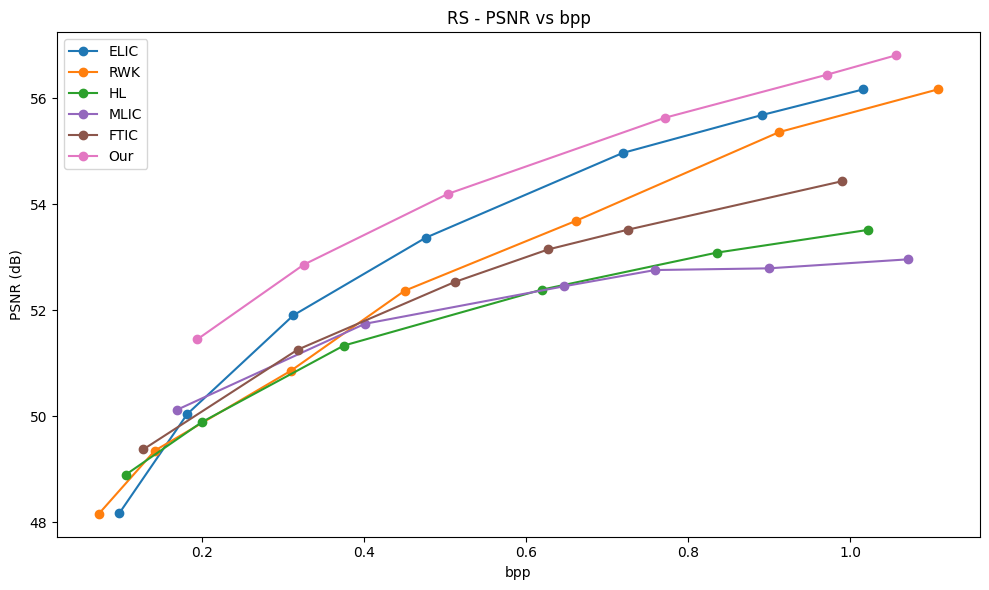

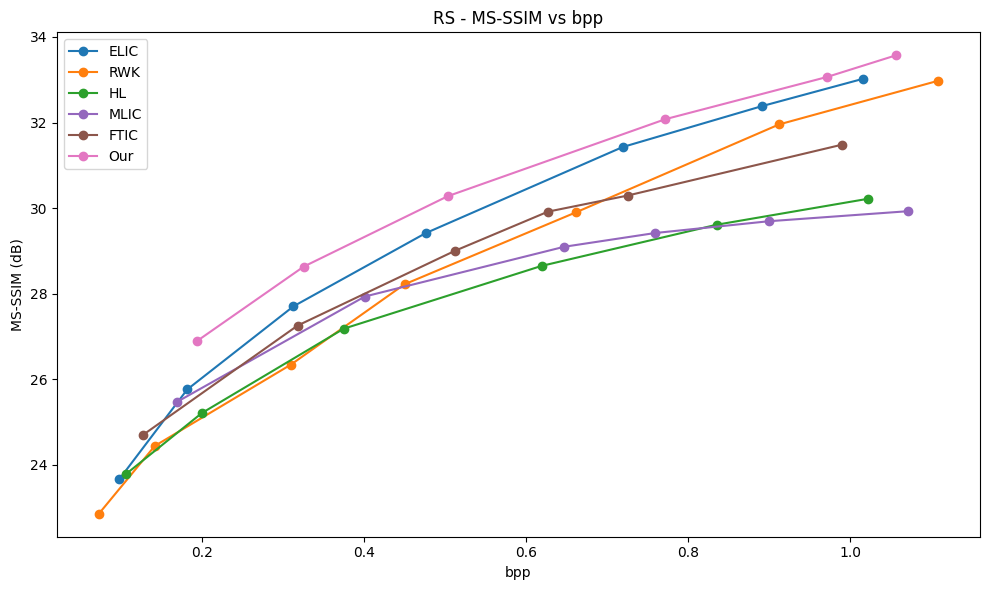

In [ ]:
import matplotlib.pyplot as plt
import math

# 将所有数据放入字典中，便于扩展
datasets = {

"ELIC": [
    (0.098, 48.167, 23.6605),
    (0.182, 50.043, 25.7634),
    (0.313, 51.908, 27.7062),
    (0.476, 53.370, 29.4158),
    (0.719, 54.970, 31.4281),
    (0.891, 55.687, 32.3851),
    (1.016, 56.171, 33.0254),

],
 "RWK" : [
    (0.073, 48.161, 22.8580),
    (0.142, 49.353, 24.4440),
    (0.310, 50.862, 26.3460),
    (0.450, 52.369, 28.2210),
    (0.662, 53.693, 29.9070),
    (0.912, 55.364, 31.9570),
    (1.108, 56.171, 32.9760),
]


,
"HL" : [  # 格式：(bpp, PSNR(dB), MSSSIM(dB))
    (0.106, 48.897, 23.7794),
    (0.200, 49.891, 25.2120),
    (0.375, 51.335, 27.1832),
    (0.619, 52.390, 28.6504),
    (0.835, 53.089, 29.6130),
    (1.021, 53.517, 30.2171),
],
 "MLIC":  [
    (0.169, 50.121, 25.4690),
    (0.401, 51.746, 27.9350),
    (0.647, 52.455, 29.0980),
    (0.759, 52.761, 29.4190),
    (0.899, 52.793, 29.6940),
    (1.071, 52.963, 29.9290),
]
,
"FTIC": [  # 仅包含λ值在 32768 到 1048576 之间的结果
 (  0.128, 49.378, 24.7090),1
 (  0.318, 51.257, 27.2550),
 (  0.512, 52.536, 29.0020),
 (  0.627, 53.149, 29.9190),
 (  0.725, 53.521, 30.2940),
 (  0.989, 54.435, 31.4810),
],



"Our"  :  [
    (0.194472, 51.454220, 26.900432),
    (0.325567, 52.861376, 28.633030),
    (0.503278, 54.197101, 30.279471),
    (0.771770, 55.637307, 32.079613),
    (0.971025, 56.447463, 33.065146),
    (1.056348, 56.814048, 33.572914),
]
}

import matplotlib.pyplot as plt

colors = {
    "ELIC": "#1f77b4",
    "RWK": "#ff7f0e",
    "HL": "#2ca02c",
    "MLIC": "#9467bd",
    "FTIC": "#8c564b",
    "Our": "#e377c2",

}

plt.figure(figsize=(10, 6))
for name, data in datasets.items():
    bpp, psnr, _ = zip(*data)
    plt.plot(bpp, psnr, label=name, marker='o', color=colors.get(name, None))
plt.xlabel("bpp")
plt.ylabel("PSNR (dB)")
plt.title("RS - PSNR vs bpp")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
for name, data in datasets.items():
    bpp, _, msssim = zip(*data)
    plt.plot(bpp, msssim, label=name, marker='o', color=colors.get(name, None))
plt.xlabel("bpp")
plt.ylabel("MS-SSIM (dB)")
plt.title("RS - MS-SSIM vs bpp")
plt.legend()
plt.tight_layout()
plt.show()


In [1]:
# RS：1217 张全测试集的已执行结果
# 格式：(BPP, PSNR(dB), MS-SSIM(dB))；BPP 为 likelihood BPP。
# Our-400 是 Hybrid-Parallel，训练上限为 400 epochs；Our-Original 是原始串行 Mamba。
# 注意：训练验证集 200 张全部包含在这 1217 张测试集中。

from pathlib import Path
import pandas as pd

result_candidates = [
    Path("results/data/full_test_rd_all_methods.csv"),
    Path("并行优化/results/data/full_test_rd_all_methods.csv"),
    Path("/data/huzhenghao/ml/h/并行优化/results/data/full_test_rd_all_methods.csv"),
]
results_csv = next(path for path in result_candidates if path.exists())
all_results = pd.read_csv(results_csv)
rs_table = all_results[all_results["Dataset"].str.lower().eq("rs")].copy()

method_labels = {
    "elic": "ELIC",
    "rwk": "RWK",
    "hl": "HL",
    "mlic": "MLIC",
    "ftic": "FTIC",
    "hpcm": "HPCM",
    "our": "Our-Original",
    "hybrid_parallel": "Our-400",
}

rs_full_test_1217 = {}
for method, group in rs_table.groupby(rs_table["Method"].str.lower()):
    label = method_labels.get(method, method)
    group = group.sort_values("bpp")
    rs_full_test_1217[label] = list(
        group[["bpp", "psnr", "ms_ssim_db"]].itertuples(index=False, name=None)
    )

print(f"source: {results_csv}")
print({name: len(points) for name, points in rs_full_test_1217.items()})
display(rs_table[["Method", "Lambda", "images", "bpp", "psnr", "ms_ssim_db"]])


source: results/data/full_test_rd_all_methods.csv
{'ELIC': 7, 'FTIC': 12, 'HL': 10, 'HPCM': 7, 'Our-400': 6, 'MLIC': 10, 'Our-Original': 6, 'RWK': 8}


,Method,Lambda,images,bpp,psnr,ms_ssim_db
56,elic,16384,1217,0.097869,48.167234,23.660542
57,elic,32768,1217,0.182256,50.042888,25.763425
58,elic,65536,1217,0.306333,51.888581,27.680210
59,elic,131071,1217,0.476949,53.331755,29.368341
60,elic,262144,1217,0.720537,54.958707,31.452550
...,...,...,...,...,...,...
117,rwk,65536,1217,0.334543,52.715454,28.542721
118,rwk,131071,1217,0.531450,54.036886,30.256784
119,rwk,262144,1217,0.836559,56.091722,32.543530
120,rwk,393216,1217,1.053710,56.887457,33.564076


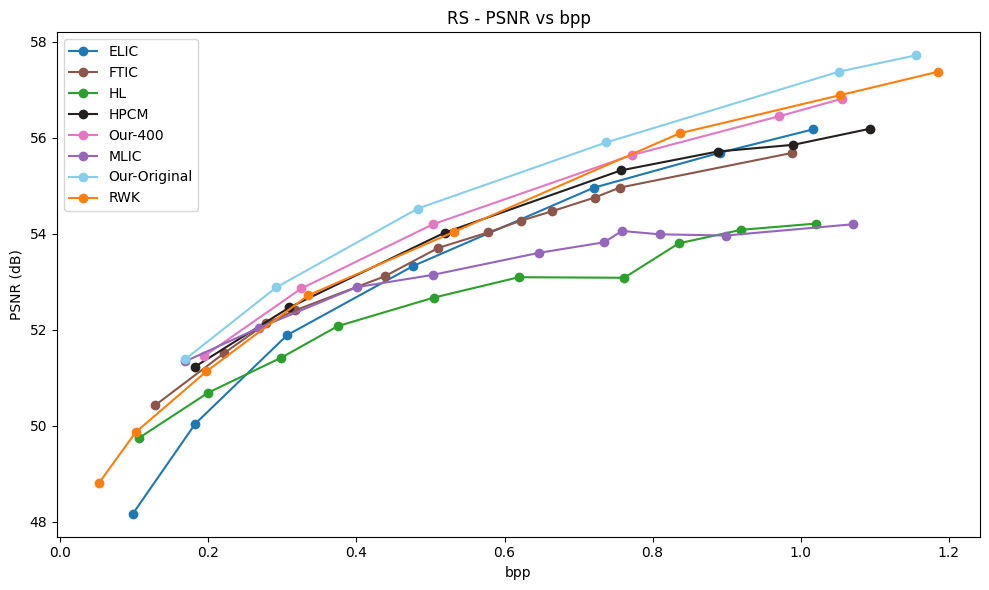

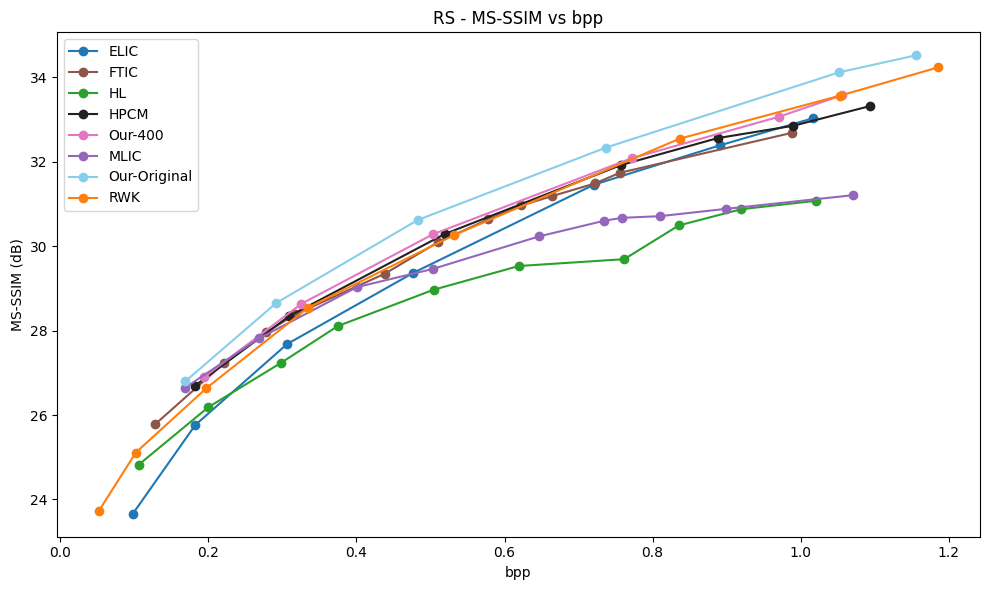

In [2]:
# 直接使用 RS 1217 张全测试集数据画图
import matplotlib.pyplot as plt

datasets = rs_full_test_1217

colors = {
    "ELIC": "#1f77b4",
    "RWK": "#ff7f0e",
    "HL": "#2ca02c",
    "MLIC": "#9467bd",
    "FTIC": "#8c564b",
    "HPCM": "#23201f",
    "Our-Original": "skyblue",
    "Our-400": "#e377c2",
}

plt.figure(figsize=(10, 6))
for name, data in datasets.items():
    bpp, psnr, _ = zip(*data)
    plt.plot(bpp, psnr, label=name, marker="o", color=colors.get(name, None))
plt.xlabel("bpp")
plt.ylabel("PSNR (dB)")
plt.title("RS - PSNR vs bpp")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
for name, data in datasets.items():
    bpp, _, msssim = zip(*data)
    plt.plot(bpp, msssim, label=name, marker="o", color=colors.get(name, None))
plt.xlabel("bpp")
plt.ylabel("MS-SSIM (dB)")
plt.title("RS - MS-SSIM vs bpp")
plt.legend()
plt.tight_layout()
plt.show()
